# Advanced Statistical Analysis & Hypothesis Testing
### Palmer Penguins: does body mass differ by species and sex?

**RabTech Academy · Data Science with Python & R Internship · Task 3**
Author: Dheena Dhayalan P

| | |
|---|---|
| **Dataset** | Palmer Penguins: 344 adult penguins measured at Palmer Station, Antarctica, 2007–2009 (Gorman, Williams & Fraser, 2014, *PLoS ONE* 9(3): e90081). Licence CC0. |
| **Outcome** | `body_mass_g`, body mass in grams |
| **Factors** | `species` (Adelie, Chinstrap, Gentoo) and `sex` (female, male) |
| **Significance level** | α = 0.05 for every test. All confidence intervals are 95% |

**Roadmap**
1. Data loading and cleaning
2. Distribution plots
3. Normality tests: Shapiro-Wilk and Kolmogorov-Smirnov (plus the Lilliefors correction)
4. Two-sample tests: Welch's t-test and Mann-Whitney U (male vs female within each species)
5. One-way ANOVA (species) with assumption checks and Tukey HSD
6. Two-way ANOVA (species × sex) with an interaction plot and Tukey HSD
7. Findings

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pingouin as pg
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

ALPHA = 0.05
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Adelie": "#E07B39", "Chinstrap": "#8E5BB5", "Gentoo": "#2A8C82"}
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

## 1. Load and clean the data

In [2]:
raw = pd.read_csv("../data/raw/penguins.csv")
print("Raw shape:", raw.shape)
raw.isna().sum().to_frame("missing values").T

Raw shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
missing values,0,0,2,2,2,2,11


Two birds have no measurements at all, and 9 more are missing `sex`. Because `sex` is a
factor in the analysis, we keep only **complete cases** for `body_mass_g` and `sex`.
That removes 11 rows (3.2%), which is small enough not to bias the comparisons
noticeably.

In [3]:
df = raw.dropna(subset=["body_mass_g", "sex"]).copy()
df["sex"] = df["sex"].str.title()
print(f"Analysis sample: n = {len(df)}  (dropped {len(raw) - len(df)})")
summary = (df.groupby(["species", "sex"])["body_mass_g"]
             .agg(n="count", mean="mean", sd="std", median="median").round(1))
summary

Analysis sample: n = 333  (dropped 11)


n  mean    sd  median
species   sex                           
Adelie    Female  73 3,369 269.4   3,400
          Male    73 4,044 346.8   4,000
Chinstrap Female  34 3,527 285.3   3,550
          Male    34 3,939 362.1   3,950
Gentoo    Female  58 4,680 281.6   4,700
          Male    61 5,485 313.2   5,500

## 2. Distribution plots

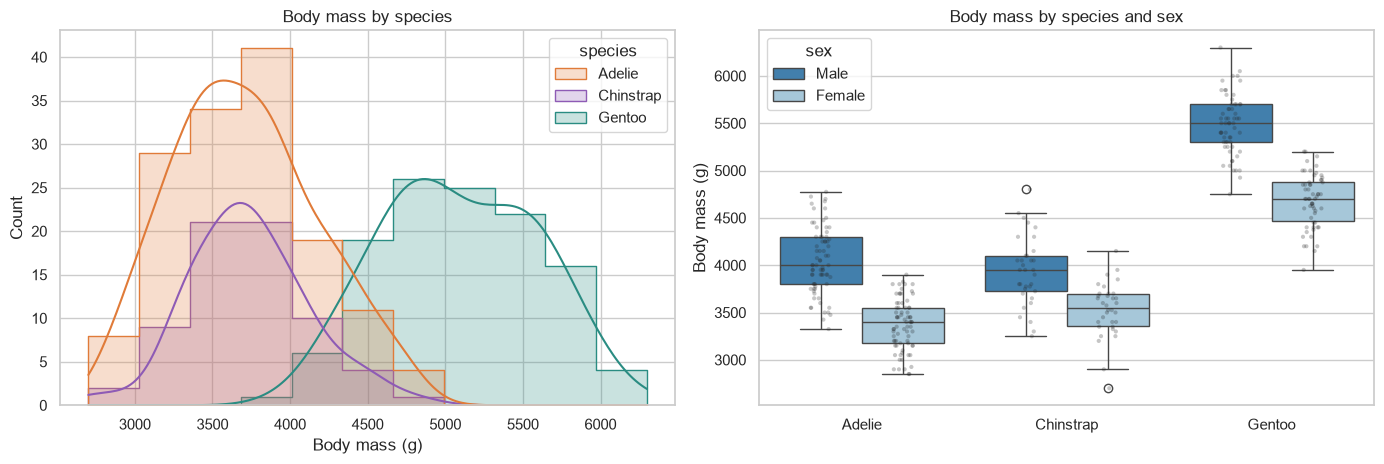

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(df, x="body_mass_g", hue="species", kde=True, palette=PALETTE,
             element="step", ax=axes[0])
axes[0].set(title="Body mass by species", xlabel="Body mass (g)")
sns.boxplot(df, x="species", y="body_mass_g", hue="sex", ax=axes[1],
            palette={"Female": "#9ECAE1", "Male": "#3182BD"})
sns.stripplot(df, x="species", y="body_mass_g", hue="sex", dodge=True, ax=axes[1],
              color="k", alpha=.25, size=3, legend=False)
axes[1].set(title="Body mass by species and sex", xlabel="", ylabel="Body mass (g)")
plt.tight_layout(); plt.savefig(FIG / "01_distributions.png", dpi=150); plt.show()

**What the plots show:** Gentoo penguins are clearly heavier than the other two species,
and Adelie and Chinstrap overlap heavily. Within every species, males sit above females.
The pooled histogram is **bimodal** (Gentoo vs the rest), so normality has to be judged
**within groups**, not on the pooled data.

## 3. Normality tests

Both tests use the same hypotheses for each group:

- **H₀:** the body masses in the group come from a normal distribution.
- **H₁:** they do not come from a normal distribution.

| Test | How it works | Notes |
|---|---|---|
| **Shapiro-Wilk** | Correlation between the ordered sample and expected normal quantiles | Most powerful general test for n < 5000 |
| **Kolmogorov-Smirnov** | Largest gap between the empirical CDF and the normal CDF | The classic KS assumes μ and σ are *known*. Plugging in the sample mean and SD makes it too lenient, so we also report the **Lilliefors** correction, which is the valid KS version when parameters are estimated |

In [5]:
rows = []
for (sp, sx), g in df.groupby(["species", "sex"]):
    x = g["body_mass_g"].to_numpy()
    z = (x - x.mean()) / x.std(ddof=1)
    sw = stats.shapiro(x)
    ks = stats.kstest(z, "norm")
    lf_stat, lf_p = lilliefors(x, dist="norm")
    rows.append({"species": sp, "sex": sx, "n": len(x),
                 "Shapiro W": sw.statistic, "Shapiro p": sw.pvalue,
                 "KS D": ks.statistic, "KS p": ks.pvalue, "Lilliefors p": lf_p})
normality = pd.DataFrame(rows)
normality["normal at α=0.05?"] = np.where(
    (normality[["Shapiro p", "Lilliefors p"]] > ALPHA).all(axis=1), "yes", "no")
normality

,species,sex,n,Shapiro W,Shapiro p,KS D,KS p,Lilliefors p,normal at α=0.05?
0,Adelie,Female,73,0.9768,0.1985,0.06861,0.8585,0.6021,yes
1,Adelie,Male,73,0.9827,0.416,0.08415,0.6483,0.2836,yes
2,Chinstrap,Female,34,0.9634,0.3055,0.09592,0.8838,0.594,yes
3,Chinstrap,Male,34,0.9841,0.891,0.09299,0.9041,0.6429,yes
4,Gentoo,Female,58,0.9813,0.5107,0.0804,0.8185,0.4954,yes
5,Gentoo,Male,61,0.9934,0.985,0.06029,0.9699,0.8696,yes


In [6]:
pooled = df["body_mass_g"]
print(f"Pooled sample (all species together): Shapiro-Wilk p = {stats.shapiro(pooled).pvalue:.2e}")

Pooled sample (all species together): Shapiro-Wilk p = 3.57e-08


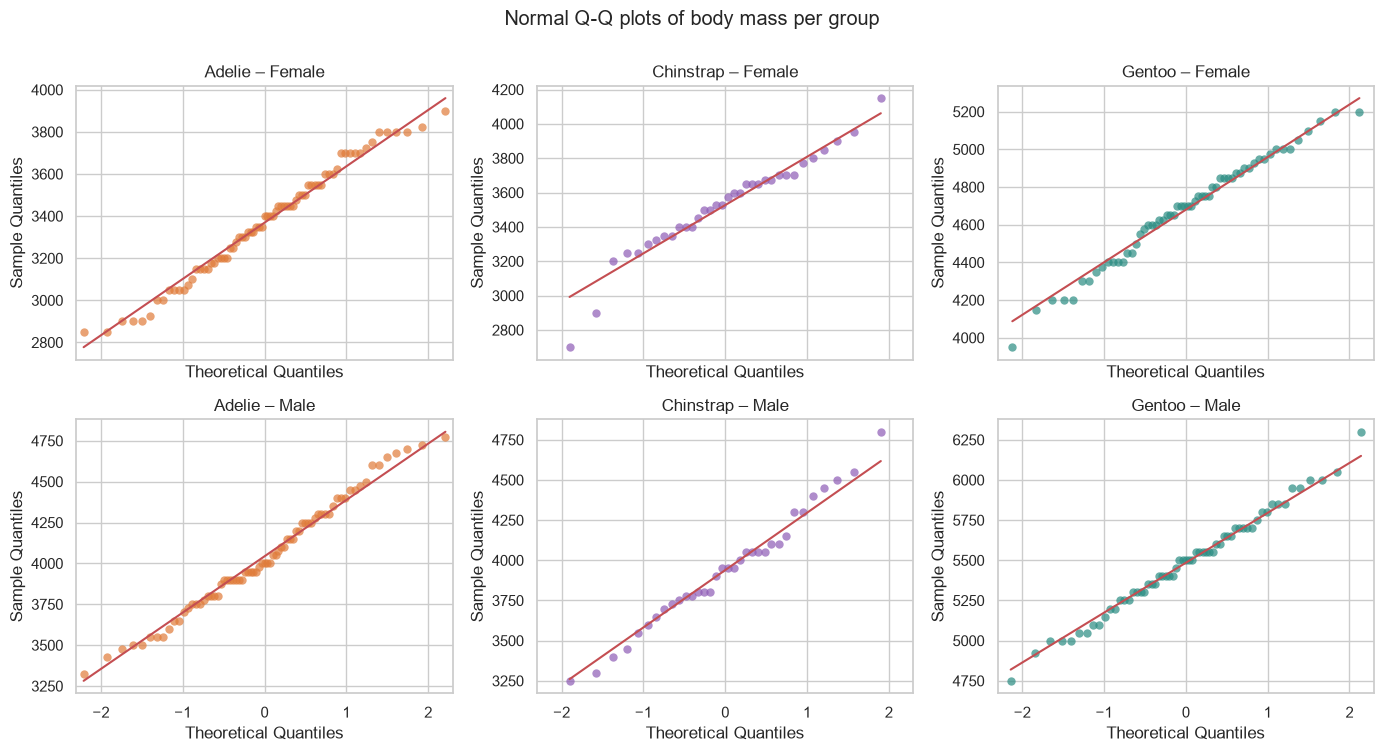

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
for ax, ((sp, sx), g) in zip(axes.T.flat, df.groupby(["species", "sex"])):
    sm.qqplot(g["body_mass_g"], line="s", ax=ax, markerfacecolor=PALETTE[sp],
              markeredgecolor="none", alpha=.7)
    ax.set_title(f"{sp} – {sx}")
fig.suptitle("Normal Q-Q plots of body mass per group", y=1.0)
plt.tight_layout(); plt.savefig(FIG / "02_qq_plots.png", dpi=150); plt.show()

**Result:** none of the six species × sex groups rejects normality (every Shapiro-Wilk and
Lilliefors p > 0.05), and the Q-Q points lie close to the reference lines. The **pooled**
data, however, strongly rejects normality (p < 0.001) because it mixes species with
different means. Parametric tests are therefore justified *within* groups, and we still
run a non-parametric test alongside each one as a check.

## 4. Two-sample tests: male vs female body mass

For each species *s*:

- **H₀:** μ_male,s = μ_female,s (the mean body masses are equal)
- **H₁:** μ_male,s ≠ μ_female,s (two-sided)

| Test | Assumption | What it compares |
|---|---|---|
| **Welch's t-test** | Normal groups (checked in §3). Does *not* assume equal variances | Means |
| **Mann-Whitney U** | None about the distribution shape | Whether a random male tends to outweigh a random female (stochastic dominance) |

Running three species means three tests per method, so p-values are adjusted with **Holm's
method** to keep the family-wise error rate at 5%. Effect size is reported as **Cohen's d**.

In [8]:
rows = []
for sp, g in df.groupby("species"):
    m = g.loc[g.sex == "Male", "body_mass_g"]
    f = g.loc[g.sex == "Female", "body_mass_g"]
    t = pg.ttest(m, f, correction=True).iloc[0]
    u = stats.mannwhitneyu(m, f, alternative="two-sided")
    rows.append({"species": sp, "n male": len(m), "n female": len(f),
                 "mean diff (g)": m.mean() - f.mean(),
                 "95% CI low": t["CI95"][0], "95% CI high": t["CI95"][1],
                 "Welch t": t["T"], "df": t["dof"], "t-test p": t["p_val"],
                 "Mann-Whitney U": u.statistic, "MWU p": u.pvalue,
                 "Levene p": stats.levene(m, f).pvalue, "Cohen's d": t["cohen_d"]})
two_sample = pd.DataFrame(rows)
two_sample["t-test p (Holm)"] = multipletests(two_sample["t-test p"], method="holm")[1]
two_sample["MWU p (Holm)"] = multipletests(two_sample["MWU p"], method="holm")[1]
two_sample["reject H₀?"] = np.where(
    (two_sample[["t-test p (Holm)", "MWU p (Holm)"]] < ALPHA).all(axis=1), "yes", "no")
two_sample.round(4)

,species,n male,n female,mean diff (g),95% CI low,95% CI high,Welch t,df,t-test p,Mann-Whitney U,MWU p,Levene p,Cohen's d,t-test p (Holm),MWU p (Holm),reject H₀?
0,Adelie,73,73,674.7,573,776.3,13.13,135.7,0,"5,018",0,0.0512,2.173,0,0,yes
1,Chinstrap,34,34,411.8,253.7,569.8,5.208,62.58,0,949.5,0,0.179,1.263,0,0,yes
2,Gentoo,61,58,805.1,697.1,913.1,14.76,116.6,0,"3,462",0,0.4497,2.7,0,0,yes


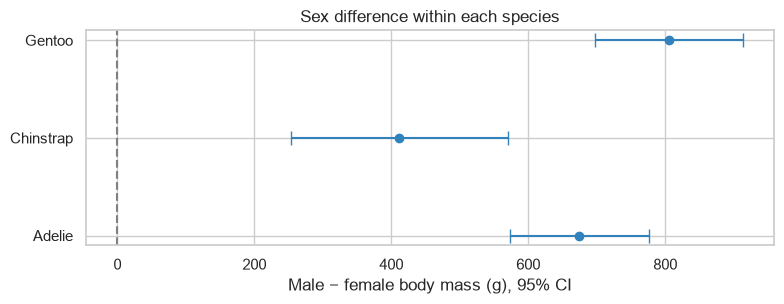

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(two_sample))
ax.errorbar(two_sample["mean diff (g)"], y,
            xerr=[two_sample["mean diff (g)"] - two_sample["95% CI low"],
                  two_sample["95% CI high"] - two_sample["mean diff (g)"]],
            fmt="o", color="#3182BD", capsize=5)
ax.axvline(0, color="grey", ls="--")
ax.set_yticks(y, two_sample["species"])
ax.set(xlabel="Male − female body mass (g), 95% CI", title="Sex difference within each species")
plt.tight_layout(); plt.savefig(FIG / "03_sex_difference_ci.png", dpi=150); plt.show()

**Result:** in all three species we **reject H₀**. Males are significantly heavier, and the
t-test and Mann-Whitney U agree even after Holm correction. No confidence interval comes
near zero.

| Species | Male − female (g) | 95% CI | Cohen's d |
|---|---|---|---|
| Adelie | ≈ 675 | ≈ [573, 776] | ≈ 2.2 (very large) |
| Chinstrap | ≈ 412 | ≈ [254, 570] | ≈ 1.3 (large) |
| Gentoo | ≈ 805 | ≈ [697, 913] | ≈ 2.7 (very large) |

The size of the gap differs by species (412 g vs 805 g). The two-way ANOVA in §6 tests
this formally as an interaction.

## 5. One-way ANOVA: does body mass differ between species?

- **H₀:** μ_Adelie = μ_Chinstrap = μ_Gentoo
- **H₁:** at least one species mean differs

The ANOVA assumes normal residuals (checked below), **equal variances** (Levene's test)
and independent observations (each row is a different bird). If variances turn out to be
unequal, **Welch's ANOVA** and the **Games-Howell** post-hoc test are the robust
alternatives. **Kruskal-Wallis** is the non-parametric counterpart.

In [10]:
groups = [g["body_mass_g"].to_numpy() for _, g in df.groupby("species")]
lev = stats.levene(*groups, center="median")
oneway_fit = smf.ols("body_mass_g ~ C(species)", df).fit()
print(f"Levene (Brown-Forsythe) equal-variance test: W = {lev.statistic:.3f}, p = {lev.pvalue:.4f}")
print(f"Shapiro-Wilk on ANOVA residuals:             p = {stats.shapiro(oneway_fit.resid).pvalue:.4f}")

Levene (Brown-Forsythe) equal-variance test: W = 5.135, p = 0.0064
Shapiro-Wilk on ANOVA residuals:             p = 0.0783


In [11]:
classic = pg.anova(df, dv="body_mass_g", between="species", detailed=True)
welch   = pg.welch_anova(df, dv="body_mass_g", between="species")
kw      = pg.kruskal(df, dv="body_mass_g", between="species")
c, w, k = classic.iloc[0], welch.iloc[0], kw.iloc[0]
oneway = pd.DataFrame({
    "test": ["Classic one-way ANOVA", "Welch ANOVA", "Kruskal-Wallis"],
    "statistic": [f"F(2, {int(classic['DF'].iloc[1])}) = {c['F']:.1f}",
                  f"F(2, {w['ddof2']:.1f}) = {w['F']:.1f}",
                  f"H(2) = {k['H']:.1f}"],
    "p": [c["p_unc"], w["p_unc"], k["p_unc"]],
    "effect size": [f"η² = {c['np2']:.3f}", f"η² = {w['np2']:.3f}", "–"],
})
oneway

,test,statistic,p,effect size
0,Classic one-way ANOVA,"F(2, 330) = 341.9",3.745e-81,η² = 0.674
1,Welch ANOVA,"F(2, 187.7) = 316.5",7.441e-61,η² = 0.674
2,Kruskal-Wallis,H(2) = 212.1,8.837e-47,–


Levene's test is significant, so the species variances are **not** equal (Gentoo varies
more). The conclusion holds either way: classic ANOVA, Welch's ANOVA and Kruskal-Wallis all
reject H₀ with p far below 0.001. **η² ≈ 0.67**: species explains about two-thirds of the
variation in body mass.

The ANOVA only says *some* mean differs. Post-hoc tests show *which* pairs do.

In [12]:
tukey1 = pairwise_tukeyhsd(df["body_mass_g"], df["species"], alpha=ALPHA)
tukey1_df = pd.DataFrame(tukey1.summary().data[1:], columns=tukey1.summary().data[0])
games = pg.pairwise_gameshowell(df, dv="body_mass_g", between="species")[["A", "B", "diff", "pval"]]
games.columns = ["group1", "group2", "Games-Howell diff", "Games-Howell p"]
games["Games-Howell diff"] *= -1  # pingouin reports A − B; Tukey reports group2 − group1
tukey1_df.merge(games, on=["group1", "group2"])

,group1,group2,meandiff,p-adj,lower,upper,reject,Games-Howell diff,Games-Howell p
0,Adelie,Chinstrap,26.92,0.9164,-132.4,186.2,False,26.92,0.8954
1,Adelie,Gentoo,"1,386",0,"1,252","1,520",True,"1,386",0
2,Chinstrap,Gentoo,"1,359",0,"1,194","1,524",True,"1,359",0


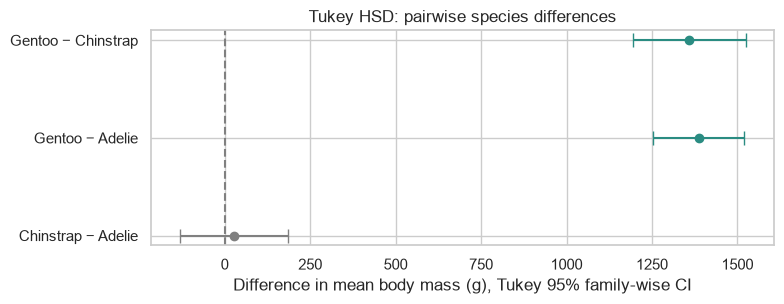

In [13]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, r in tukey1_df.iterrows():
    color = "#2A8C82" if r["reject"] else "grey"
    ax.errorbar(r["meandiff"], i, xerr=[[r["meandiff"] - r["lower"]], [r["upper"] - r["meandiff"]]],
                fmt="o", color=color, capsize=5)
ax.axvline(0, color="grey", ls="--")
ax.set_yticks(range(len(tukey1_df)), tukey1_df["group2"] + " − " + tukey1_df["group1"])
ax.set(xlabel="Difference in mean body mass (g), Tukey 95% family-wise CI",
       title="Tukey HSD: pairwise species differences")
plt.tight_layout(); plt.savefig(FIG / "04_tukey_species.png", dpi=150); plt.show()

**Post-hoc result:**
- **Gentoo vs Adelie:** Gentoo is ≈ 1,386 g heavier (significant)
- **Gentoo vs Chinstrap:** Gentoo is ≈ 1,359 g heavier (significant)
- **Chinstrap vs Adelie:** a difference of only ≈ 27 g, with a CI that spans zero (p ≈ 0.92).
  **Not significant.**

Games-Howell, which does not assume equal variances, gives the same three decisions, so the
unequal variances do not change the conclusions.

## 6. Two-way ANOVA: species × sex

Model: `body_mass_g ~ species + sex + species:sex`. The group sizes are unequal, so we use
**Type II sums of squares**. Three pairs of hypotheses:

| Effect | H₀ | H₁ |
|---|---|---|
| Species (main) | Species means are equal, averaging over sex | At least one differs |
| Sex (main) | Male and female means are equal, averaging over species | They differ |
| **Species × sex (interaction)** | The male−female gap is **the same** in every species | The gap **depends** on species |

In [14]:
twoway_fit = smf.ols("body_mass_g ~ C(species) * C(sex)", df).fit()
twoway = sm.stats.anova_lm(twoway_fit, typ=2)
twoway["partial η²"] = twoway["sum_sq"] / (twoway["sum_sq"] + twoway.loc["Residual", "sum_sq"])
twoway.loc["Residual", "partial η²"] = np.nan
print(f"Residual Shapiro-Wilk p = {stats.shapiro(twoway_fit.resid).pvalue:.3f}  |  "
      f"Levene across 6 cells p = {stats.levene(*[g.body_mass_g for _, g in df.groupby(['species','sex'])], center='median').pvalue:.3f}")
twoway

Residual Shapiro-Wilk p = 0.937  |  Levene across 6 cells p = 0.227


,sum_sq,df,F,PR(>F),partial η²
C(species),1.434e+08,2,749,8.144e-123,0.8208
C(sex),3.709e+07,1,387.5,1.902e-57,0.5423
C(species):C(sex),1.677e+06,2,8.757,0.0001973,0.05084
Residual,3.13e+07,327,NaN,NaN,NaN


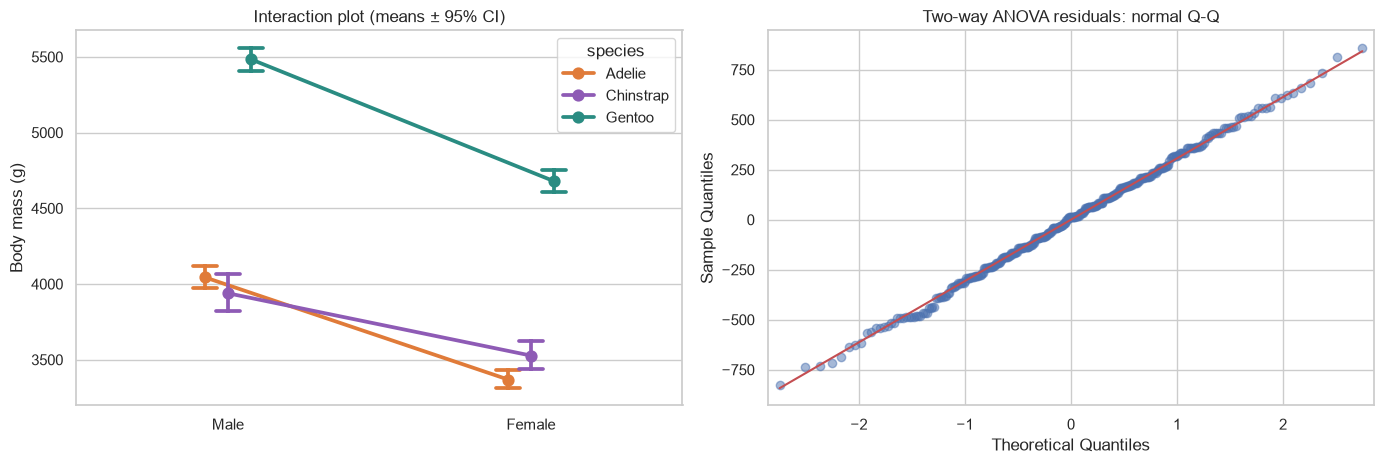

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.pointplot(df, x="sex", y="body_mass_g", hue="species", palette=PALETTE,
              errorbar=("ci", 95), dodge=.15, capsize=.08, ax=axes[0])
axes[0].set(title="Interaction plot (means ± 95% CI)", ylabel="Body mass (g)", xlabel="")
sm.qqplot(twoway_fit.resid, line="s", ax=axes[1], alpha=.5)
axes[1].set_title("Two-way ANOVA residuals: normal Q-Q")
plt.tight_layout(); plt.savefig(FIG / "05_interaction_and_residuals.png", dpi=150); plt.show()

**Result:** all three effects are significant.
- **Species:** F ≈ 749, p < 0.001, partial η² ≈ 0.82
- **Sex:** F ≈ 387, p < 0.001, partial η² ≈ 0.54
- **Interaction:** F ≈ 8.8, p ≈ 0.0002, partial η² ≈ 0.05. It is small but real: the lines
  in the interaction plot are **not parallel**. Gentoo has the steepest female→male slope
  and Chinstrap the flattest.

The residuals are close to normal (Shapiro p ≈ 0.94), so the model assumptions hold.

Because the interaction is significant, the main effects should not be read on their own.
The Tukey HSD on all six species × sex cells below gives the full picture.

In [16]:
df["group"] = df["species"] + " " + df["sex"]
tukey2 = pairwise_tukeyhsd(df["body_mass_g"], df["group"], alpha=ALPHA)
tukey2_df = pd.DataFrame(tukey2.summary().data[1:], columns=tukey2.summary().data[0])
tukey2_df.sort_values("p-adj", ascending=False).reset_index(drop=True)

,group1,group2,meandiff,p-adj,lower,upper,reject
0,Adelie Male,Chinstrap Male,-104.5,0.5812,-288.7,79.64,False
1,Adelie Female,Chinstrap Female,158.4,0.1376,-25.79,342.5,False
2,Adelie Female,Adelie Male,674.7,0,527.8,821.5,True
3,Adelie Female,Chinstrap Male,570.1,0,386,754.3,True
4,Adelie Female,Gentoo Female,"1,311",0,"1,155","1,467",True
5,Adelie Female,Gentoo Male,"2,116",0,"1,962","2,270",True
6,Adelie Male,Chinstrap Female,-516.3,0,-700.4,-332.1,True
7,Adelie Male,Gentoo Female,636.2,0,480.2,792.3,True
8,Adelie Male,Gentoo Male,"1,441",0,"1,287","1,595",True
9,Chinstrap Female,Chinstrap Male,411.8,0,196.6,626.9,True


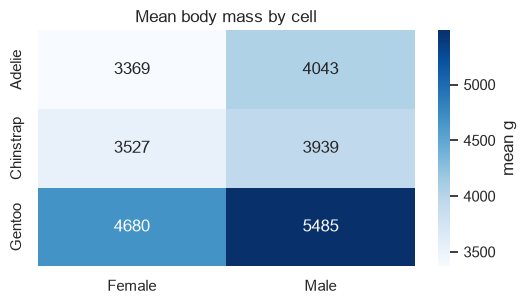

In [17]:
cell_means = df.pivot_table(index="species", columns="sex", values="body_mass_g", aggfunc="mean")
fig, ax = plt.subplots(figsize=(5.5, 3.2))
sns.heatmap(cell_means, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "mean g"}, ax=ax)
ax.set(title="Mean body mass by cell", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "06_cell_means.png", dpi=150); plt.show()

Of the 15 cell pairs, Tukey finds only **two non-significant** differences:
- **Adelie female vs Chinstrap female** (≈ 158 g, p ≈ 0.14)
- **Adelie male vs Chinstrap male** (≈ 105 g, p ≈ 0.58)

So once sex is matched, Adelie and Chinstrap are statistically indistinguishable, which
matches §5. Every Gentoo cell differs from every other cell.

## 7. Findings

| # | Question | Test(s) | Decision (α = 0.05) | Key numbers |
|---|---|---|---|---|
| 1 | Is body mass normal within each species × sex group? | Shapiro-Wilk, KS, Lilliefors | Fail to reject H₀ in **all 6 groups** | all p > 0.05 |
| 2 | Are males heavier than females? | Welch t, Mann-Whitney U (Holm) | **Reject H₀** in all 3 species | +412 to +805 g, d = 1.3–2.7 |
| 3 | Does mass differ between species? | One-way, Welch ANOVA, Kruskal-Wallis | **Reject H₀** | η² ≈ 0.67 |
| 3a | Which species differ? | Tukey HSD, Games-Howell | Gentoo ≠ Adelie, Gentoo ≠ Chinstrap; **Adelie ≈ Chinstrap** | Gentoo ≈ +1.36–1.39 kg |
| 4 | Does the sex gap depend on species? | Two-way ANOVA (Type II) | **Reject H₀** (interaction) | F ≈ 8.8, p ≈ 0.0002 |

**Conclusions**
1. **Species is the dominant driver of body mass.** Gentoo penguins are about 1.4 kg heavier than
   Adelie or Chinstrap, which do not differ from each other.
2. **Sexual size dimorphism is present in all three species,** with very large standardized effects.
3. **The degree of dimorphism depends on species.** It is largest in Gentoo (≈ 805 g) and
   smallest in Chinstrap (≈ 412 g), so a model that ignores the interaction would misstate
   the sex effect for every species.
4. **Parametric and non-parametric methods agree everywhere,** so the conclusions do not depend
   on the normality or equal-variance assumptions.

**Limitations**
- This is an observational dataset, so the differences describe these populations and do not
  explain their causes.
- 11 birds with missing sex were excluded.
- Levene's test showed unequal variances between species. This was handled with Welch's ANOVA
  and Games-Howell, which agreed with the classic results.
- Birds were sampled over 3 years and 3 islands. Year and island were not modelled.